In [1]:
import math
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from optical_communication_system.components import *
from optical_communication_system.components.utils import normalize_signal, psk_constellation, symbol_mapping_to_gray
from optical_communication_system.plot import *

2024-09-25 21:40:33.533148: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-09-25 21:40:33.585470: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-09-25 21:40:33.585497: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-09-25 21:40:33.586728: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-09-25 21:40:33.592731: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2024-09-25 21:40:33.593327: I tensorflow/core/platform/cpu_feature_guard.cc:1

In [2]:
Component.trace_debug_enabled_by_default = True

data_rate = 1e9
sampling_rate = data_rate * 10
central_frequency = 193.414e12 # Hz

input_power = 2e-3 # Watts

lpf = BandPassFilter(min_frequency=0.0, max_frequency=1 * data_rate, name="lpf")

qam4_mapping = symbol_mapping_to_gray([
    [-1.0, -1.0], [-1.0, 1.0],
    [ 1.0, -1.0], [ 1.0, 1.0]
])

qam16_mapping = symbol_mapping_to_gray([
    [-1.0,  1.0], [-1.0,  0.5], [-1.0, -0.5], [-1.0, -1.0],
    [-0.5, -1.0], [-0.5, -0.5], [-0.5,  0.5], [-0.5,  1.0],
    [ 0.5,  1.0], [ 0.5,  0.5], [ 0.5, -0.5], [ 0.5, -1.0],
    [ 1.0, -1.0], [ 1.0, -0.5], [ 1.0,  0.5], [ 1.0,  1.0]
])

psk4_mapping = symbol_mapping_to_gray(psk_constellation(2))
psk16_mapping = symbol_mapping_to_gray(psk_constellation(4))
psk256_mapping = symbol_mapping_to_gray(psk_constellation(8))

bits_per_symbol, symbol_mapping = 4, qam16_mapping

snr = 30.0

system = Composition(components=[
    IQEncoder(
        sampling_rate=sampling_rate,
        data_rate=data_rate,
        symbol_encoder=IQSymbolEncoder(
            bits_per_symbol=bits_per_symbol,
            mapping=symbol_mapping,
            adjust_for_mzm=True,
            name="iq_symbol_encoder"
        )
    ),  # (ElectricalSignal, ElectricalSignal)
    MapComponent(component=lpf, name="encoder_output"),  # (ElectricalSignal, ElectricalSignal)
    IQModulator(
        carrier_source=Laser(power=input_power, name="laser"),
        name="modulator"
    ),  # OpticalSignal
    OpticalAWGN(power=input_power / 10 ** (snr * 0.1), name="modulator_output"),  # OpticalSignal
    OpticalFiber(
        attenuation=0.22,
        length=40.0,
        chromatic_dispersion=17.0,
        eff_non_linear_coeff=1.76,
        central_frequency=central_frequency,
        step_count=1000,
        name="channel"
    ),  # OpticalSignal
    IQReceiver(
        photodiode=Composition(components=[Photodiode(), lpf]),
        local_oscillator=Laser(power=2e-3),
        name="receiver_output"
    ),  # (ElectricalSignal, ElectricalSignal)
    IQDecoder(
        data_rate=data_rate,
        symbol_decoder=IQSymbolDecoder(
            bits_per_symbol=bits_per_symbol,
            mapping=qam16_mapping,
            name="iq_symbol_decoder"
        ),
        name="decoder_output"
    ) # tf.TensorSpec(shape=[None], dtype=tf.int32)
]) # tf.TensorSpec(shape=[None], dtype=tf.int32)

rng = tf.random.Generator.from_non_deterministic_state(alg="philox")
ber_tester = BERTester([system])

In [3]:
input_signal = tf.constant([1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1], dtype=tf.int32)
input_signal = rng.uniform((512,), 0, 2, dtype=tf.int32)

system_params = dict(
    channel__step_count=tf.constant(10000),
    channel__length=tf.constant(5.0),
    channel__eff_non_linear_coeff=tf.constant(1.76 * 10e4),
    iq_symbol_encoder__mapping=tf.constant(qam16_mapping),
    iq_symbol_decoder__mapping=tf.constant(qam16_mapping),
    iq_symbol_encoder__bits_per_symbol=tf.constant(4),
    iq_symbol_decoder__bits_per_symbol=tf.constant(4)
)

system.trace(input_signal, **system_params)

Calling Composition(name='composition') with args tf.Tensor(shape=[512], dtype=tf.int32)
|---Calling IQEncoder(name='iq_encoder') with args tf.Tensor(shape=[512], dtype=tf.int32)
|---|---Return tuple[ElectricalSignal, ElectricalSignal]
|---Calling MapComponent(name='encoder_output') with args tuple[ElectricalSignal, ElectricalSignal]
|---|---Calling BandPassFilter(name='lpf') with args ElectricalSignal
|---|---|---Return ElectricalSignal
|---|---Calling BandPassFilter(name='lpf') with args ElectricalSignal
|---|---|---Return ElectricalSignal
|---|---Return tuple[ElectricalSignal, ElectricalSignal]
|---Calling IQModulator(name='modulator') with args tuple[ElectricalSignal, ElectricalSignal]
|---|---Calling MapComponents(name='map_components') with args tuple[ElectricalSignal, ElectricalSignal]
|---|---|---Calling MachZehnderModulator(name='mach_zehnder_modulator') with args ElectricalSignal
|---|---|---|---Return OpticalSignal
|---|---|---Calling MachZehnderModulator(name='mach_zehnder_

<tf.Tensor: shape=(512,), dtype=int32, numpy=
array([1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1,
       0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 1, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1,
       1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0,
       1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0,
       0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0,
       1, 0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0,
       1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1,
       0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 1,
     

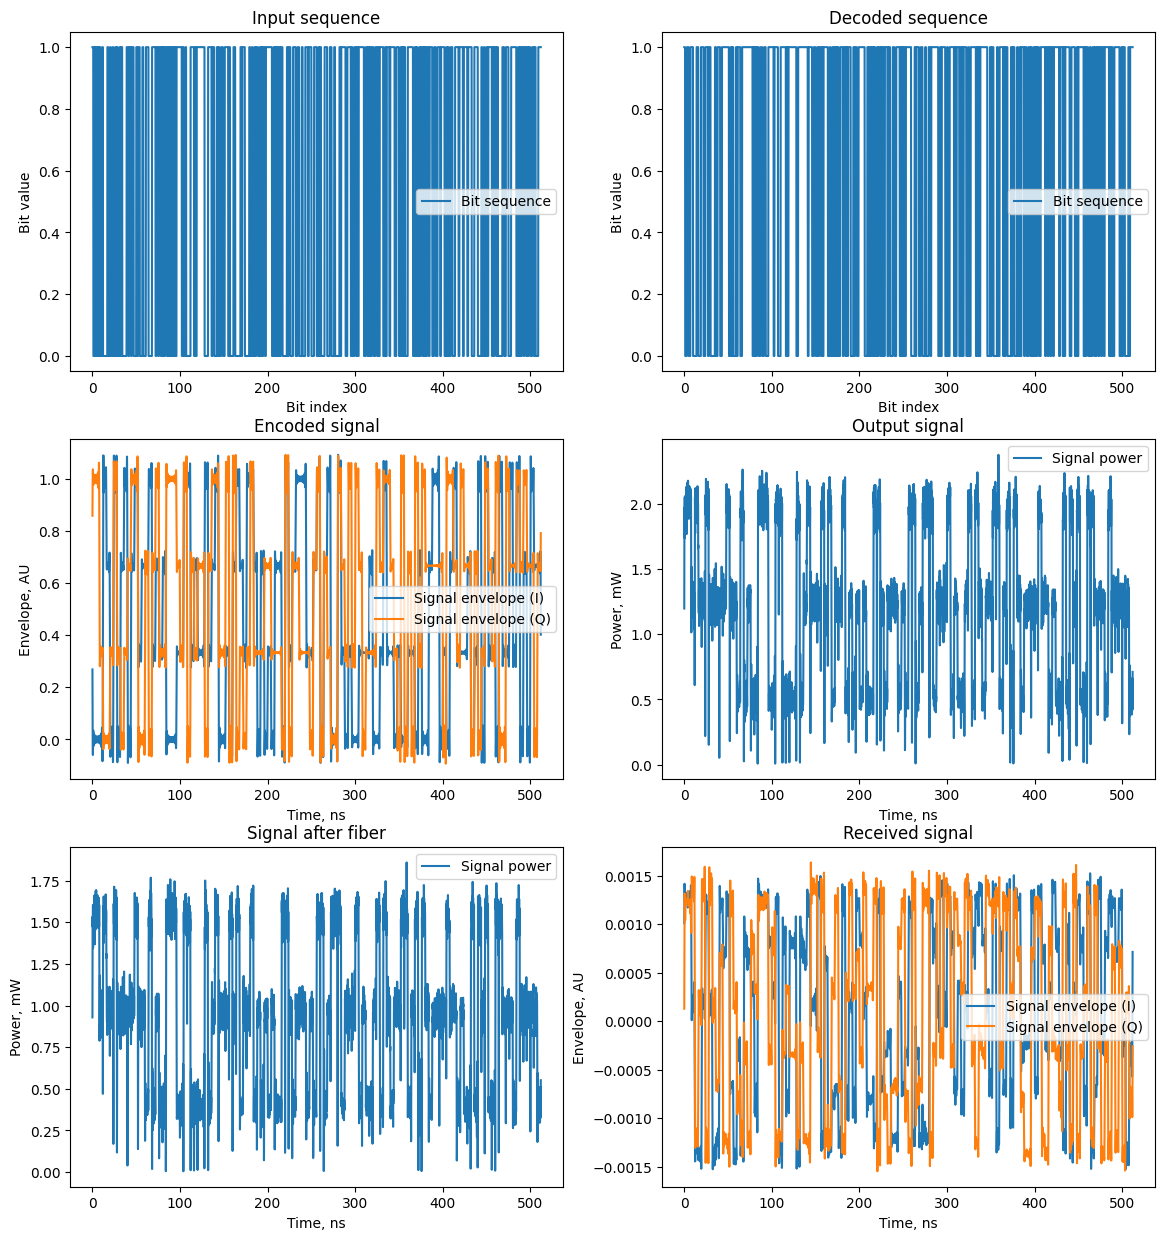

In [4]:
fig, ((input_ax, decoded_ax), (encoded_ax, output_ax), (fiber_ax, received_ax)) = plt.subplots(3, 2)  # type: ignore
fig.set_size_inches(14, 15)

axes = [
    (input_ax, "Input sequence"),
    (encoded_ax, "Encoded signal"),
    (output_ax, "Output signal"),
    (fiber_ax, "Signal after fiber"),
    (received_ax, "Received signal"),
    (decoded_ax, "Decoded sequence")
]

plot_bitseq(input_signal, input_ax)
plot_envelope(system.find_child("encoder_output").output, encoded_ax)
plot_power(system.find_child("modulator_output").output, output_ax)
plot_power(system.find_child("channel").output, fiber_ax)

plot_envelope(system.find_child("receiver_output").output, received_ax)

plot_bitseq(system.output, decoded_ax)

for ax, title in axes:
    ax.set_title(title)
    ax.legend()

(-1.3447011947631835,
 1.4595635056495668,
 -1.3664927661418915,
 1.4377719342708588)

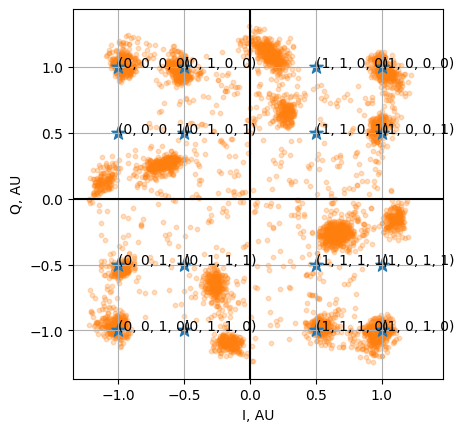

In [5]:
plt.axhline(0.0, color="black")
plt.axvline(0.0, color="black")
plt.grid()
plot_iq_constellation(system.find_child("receiver_output").output, s=10, iq_units=(0.8e3, "AU"), alpha=0.25, color="tab:orange")
plot_iq_constellation(tf.constant(symbol_mapping), s=100, marker="*", color="tab:blue")

annotate_constellation = True

if annotate_constellation:
    for i, symbol in enumerate(symbol_mapping):
        bit_string = ', '.join(
            tuple(
                bin(i)[2:].zfill(
                    int(bits_per_symbol)
                )
            )
        )
    
        plt.annotate(f"({bit_string})", (symbol[0], symbol[1]))

plt.axis("square")

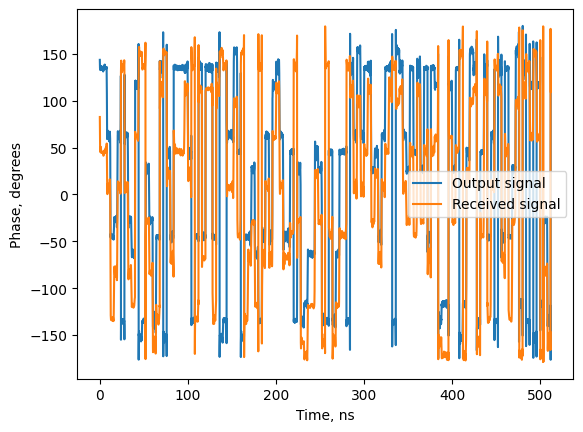

In [6]:
plot_phase(system.find_child("modulator_output").output, label="Output signal")
plot_phase(system.find_child("receiver_output").output, label="Received signal")
plt.legend()

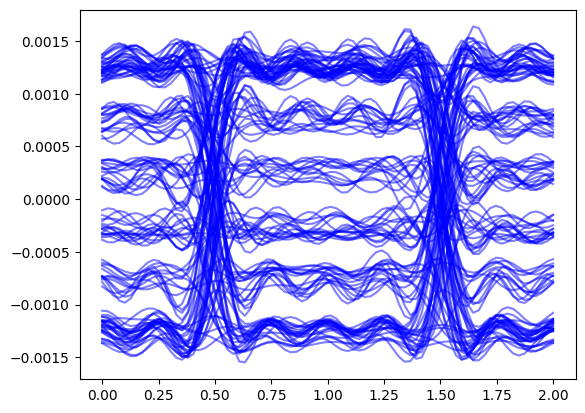

In [7]:
for signal in system.find_child("receiver_output").output:
    plot_eye_diagram(signal, color="blue", alpha=0.5)

In [ ]:
%time ber_tester(tf.constant(128), **system_params)